# Week 13 Demo 1: Classification Methods with Healthcare Readmission Data
## KNN, SVM, Kernels, and Classification Metrics

**Dataset:** `healthcare_readmission.csv`  
**Target:** `readmitted_30d` where 1 means readmitted within 30 days

### Business context
A healthcare organization wants to identify patients who may benefit from additional discharge support or follow-up. The model is an instructional risk-classification tool, not a diagnosis and not a replacement for professional judgment.

The two error types have different implications. A **false negative** occurs when the model predicts no readmission for a patient who is actually readmitted within 30 days. A **false positive** occurs when the model flags a patient who is not readmitted, which may consume limited follow-up capacity. This is why accuracy alone is inadequate.

> The full file contains 120,500 records and a minority readmission class. We use a stratified sample so SVM runs comfortably during class while preserving the outcome ratio.

## Learning Objectives for Demo 1

By the end of this class, you should be able to:

1. **Explain the basic ideas behind KNN and SVM classification**, including neighbours, margins, and kernels.
2. **Explain why feature scaling matters for KNN and SVM** and apply scaling before modelling.
3. **Compare KNN and SVM classification results** using a confusion matrix, precision, recall, and F1 score.
4. **Interpret false positives and false negatives** in the healthcare readmission problem and explain which errors matter for the Term Project decision.

### Week 13 resources

**Lectures 23–24 – Classification Methods**
- [Lecture recording 1](https://nait.video.yuja.com/V/Video?v=1347085&node=7565253&a=307056772)
- [Lecture presentation](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551468)
- [Lecture recording 2](https://nait.video.yuja.com/V/Video?v=1347388&node=7565686&a=2094119733)
- [Lecture 23–24 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture23-24_classification_methods.ipynb)
- [Lecture 23–24 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture23_24_workbook.ipynb)
- [Workbook solution](https://colab.research.google.com/drive/1L-Km8EqpPdVGZZxreSbt83LwP_6GjjZu?usp=sharing)

**Readings – Machine Learning with Python for Everyone**
- [Book access through NAIT/O'Reilly](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)
- [Chapter 8 – More Classification Methods](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/ch08.xhtml#ch08)
- [Chapter 10 – Manual Feature Engineering](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/ch10.xhtml#ch10)
- **Chapter 11 – Tuning Hyperparameters and Pipelines** through the same O'Reilly book.

## Connection to the Term Project

This demo is also a worked example of the reasoning expected in the **DATA 3320 Term Project**. The term project asks you to move beyond running an algorithm: you should discover a meaningful story in the data, analyze that story, and communicate it clearly.

As you work through this notebook, notice the project habits being modelled:

1. **Start with a decision-oriented question.** Here the question is whether available patient information can help identify higher risk of 30-day readmission. In your project, state the outcome or business question before choosing an algorithm.
2. **Audit the data before modelling.** In this healthcare file, missing values, inconsistent category labels, implausible values, and identifiers need attention. Your project should document what was found and justify how it was handled.
3. **Choose predictors deliberately.** Do not include a field simply because it exists. Explain why it may help answer the question and whether it would actually be available when a prediction is made.
4. **Establish a baseline.** Because readmission is imbalanced, accuracy by itself can be deceptive. Your project should show what a simple baseline would achieve before claiming that a machine-learning model performs well.
5. **Compare alternatives.** KNN and SVM provide two different approaches here. In the project, compare appropriate candidate models rather than presenting only the final one.
6. **Interpret metrics in context.** A false negative and false positive have different implications. Connect precision, recall, F1, or another chosen metric to the decision your project is meant to support.
7. **Tell the story.** Your final project should connect the business question → data issues → modelling choices → evidence → limitations → recommendation.

> **Project connection:** Do not copy this healthcare workflow mechanically. Use it as a model for how to justify your own decisions. A strong project explains *why* each step is appropriate for its particular dataset and question.

## Loading the Main Libraries

Run the next cell first. It imports only the three libraries needed to load and inspect the data:

- `numpy` for numerical operations and missing values;
- `pandas` for loading and working with the dataset;
- `matplotlib` for charts.

The cell prints **“Libraries loaded successfully.”** when it finishes. The scikit-learn tools are imported later, immediately before they are used. This keeps the first cell short and makes errors easier to identify.

## 1. Load the data

Keep `healthcare_readmission.csv` in the **same folder as this notebook** before running the cell.

In [7]:
# Import the main libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the results reproducible
RANDOM_STATE = 42

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Loading the Healthcare Dataset

Place `healthcare_readmission.csv` in the **same folder as the notebook**, then run the next cell.

If you are using Google Colab, upload `healthcare_readmission.csv` to the Colab session before running the cell. If the file is missing, Python will display a `FileNotFoundError`; that means the file needs to be uploaded or moved beside the notebook.

In [9]:
# Load the healthcare dataset
# The CSV file must be in the same folder as this notebook.
df = pd.read_csv("healthcare_readmission.csv")

print(f"Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Dataset loaded: 120,500 rows and 17 columns


,patient_id,age,gender,region,bmi,systolic_bp,cholesterol_mmol_l,hba1c_pct,smoker_status,activity_level,chronic_conditions,prior_admissions,avg_visit_cost,insurance_type,appointment_wait_days,missed_appointments,readmitted_30d
0,P0000001,57,Male,Calgary,30.5,132.0,3.44,7.4,Former,Moderate,2,0,687.67,Employer,19,0,0
1,P0000002,34,Male,Southern Alberta,21.9,164.0,3.69,5.1,Never,Moderate,2,0,522.70,Employer,4,1,0
2,P0000003,65,Male,Calgary,29.5,141.0,3.98,7.1,Former,Moderate,0,0,239.01,Employer,7,0,0
3,P0000004,68,Male,Calgary,29.3,146.0,6.60,5.2,Never,Low,2,0,478.34,Employer,4,0,0
4,P0000005,19,Male,Edmonton,36.4,146.0,4.52,5.8,Never,Moderate,1,0,494.69,Government,6,0,0


## 2. Inspect before modelling

Review data types, missingness, ranges, and category labels before building a model. `patient_id` is an identifier and should not be treated as a predictor.

In [11]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120500 entries, 0 to 120499
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   patient_id             120500 non-null  object 
 1   age                    118497 non-null  object 
 2   gender                 117751 non-null  object 
 3   region                 119070 non-null  object 
 4   bmi                    116206 non-null  object 
 5   systolic_bp            116904 non-null  float64
 6   cholesterol_mmol_l     117780 non-null  object 
 7   hba1c_pct              115703 non-null  object 
 8   smoker_status          118437 non-null  object 
 9   activity_level         116977 non-null  object 
 10  chronic_conditions     120500 non-null  int64  
 11  prior_admissions       120500 non-null  int64  
 12  avg_visit_cost         119027 non-null  object 
 13  insurance_type         117551 non-null  object 
 14  appointment_wait_days  120500 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,120500,120000,P0089934,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,118497,78,18,2862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,117751,12,Female,56624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,119070,15,Edmonton,38414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,116206,355,unknown,2297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
systolic_bp,116904.0,NaN,NaN,NaN,127.768023,39.210834,0.0,115.0,126.0,138.0,999.0
cholesterol_mmol_l,117780,626,unknown,2703,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hba1c_pct,115703,61,5.8,5011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker_status,118437,12,Never,65493,NaN,NaN,NaN,NaN,NaN,NaN,NaN
activity_level,116977,9,Moderate,54614,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean category labels

The source includes capitalization, whitespace, abbreviations, blanks, and placeholders. Without normalization, one-hot encoding would interpret equivalent labels as different categories. Missing predictors remain for later imputation; rows missing the supervised target cannot be used.

### Important data-quality distinction
Standardizing labels such as `Female`, `female`, and values with extra spaces is a defensible cleaning step because the representation changes while the underlying category does not. By contrast, values such as a negative age, BMI of 0, systolic blood pressure of 999, or a negative visit cost require a **validation rule and an explicit decision**. In this demo, clearly impossible values are converted to missing values using broad data-validity bounds and then imputed from the training data. These bounds are used to prevent obvious data-entry errors from entering the model; they are **not clinical cutoffs**. In the term project, document your validation rules and show how they affect the usable sample.


In [13]:
def clean_data(df):
    """Clean labels and replace clearly invalid values with missing values."""
    data = df.copy()

    # Make column names consistent
    data.columns = data.columns.str.strip().str.lower()

    # Clean text columns
    text_columns = [
        "gender",
        "region",
        "smoker_status",
        "activity_level",
        "insurance_type"
    ]

    for column in text_columns:
        data[column] = data[column].astype("string").str.strip().str.lower()
        data[column] = data[column].replace(
            {"": np.nan, "n/a": np.nan, "unknown": np.nan}
        )
        data[column] = data[column].astype(object)

    # Combine labels that mean the same thing
    data["gender"] = data["gender"].replace({
        "f": "female",
        "m": "male",
        "nb": "non-binary",
        "nonbinary": "non-binary"
    })

    data["region"] = data["region"].replace({
        "edm": "edmonton",
        "yyc": "calgary",
        "north": "northern alberta",
        "south": "southern alberta"
    })

    data["smoker_status"] = data["smoker_status"].replace({
        "n": "never",
        "y": "current"
    })

    data["insurance_type"] = data["insurance_type"].replace({
        "govt": "government",
        "un-insured": "uninsured"
    })

    # Convert measurement columns to numeric values
    numeric_columns = [
        "age", "bmi", "systolic_bp", "cholesterol_mmol_l",
        "hba1c_pct", "chronic_conditions", "prior_admissions",
        "avg_visit_cost", "appointment_wait_days",
        "missed_appointments", "readmitted_30d"
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    # Replace clearly impossible values with missing values
    data.loc[(data["age"] < 0) | (data["age"] > 120), "age"] = np.nan
    data.loc[(data["bmi"] <= 0) | (data["bmi"] > 100), "bmi"] = np.nan
    data.loc[(data["systolic_bp"] <= 0) | (data["systolic_bp"] > 300), "systolic_bp"] = np.nan
    data.loc[(data["cholesterol_mmol_l"] <= 0) | (data["cholesterol_mmol_l"] > 20), "cholesterol_mmol_l"] = np.nan
    data.loc[(data["hba1c_pct"] <= 0) | (data["hba1c_pct"] > 25), "hba1c_pct"] = np.nan
    data.loc[(data["avg_visit_cost"] < 0) | (data["avg_visit_cost"] > 50000), "avg_visit_cost"] = np.nan

    # The target must be available for supervised learning
    data = data.dropna(subset=["readmitted_30d"])
    data["readmitted_30d"] = data["readmitted_30d"].astype(int)

    return data


healthcare = clean_data(df)

print(f"Rows after cleaning: {len(healthcare):,}")
print(f"Readmission rate: {healthcare['readmitted_30d'].mean():.1%}")

Rows after cleaning: 120,500
Readmission rate: 14.4%


## 4. Examine class imbalance

Most records are not readmitted. A majority-class model can look accurate while identifying no readmissions. Precision, recall, and F1 provide a more informative view of the positive class.

In [15]:
class_counts = healthcare["readmitted_30d"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "count": class_counts,
    "percent": class_counts / class_counts.sum()
})

print(class_summary)
print(f"Majority-class baseline: {class_counts.max() / class_counts.sum():.1%}")

                 count   percent
readmitted_30d                  
0               103096  0.855568
1                17404  0.144432
Majority-class baseline: 85.6%


## 5. Select numeric predictors and create a stratified sample

Demo 1 uses numeric variables to isolate the behaviour of KNN and SVM. Stratification preserves the original readmission proportion in the sample and train-test split. The test set represents unseen patients.

In [17]:
from sklearn.model_selection import train_test_split

features = ["age","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","chronic_conditions","prior_admissions","avg_visit_cost","appointment_wait_days","missed_appointments"]
X = healthcare[features]
y = healthcare["readmitted_30d"]
X, _, y, _ = train_test_split(
    X, y, train_size=15000, stratify=y, random_state=RANDOM_STATE
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape,X_test.shape,y_train.mean())

(11250, 10) (3750, 10) 0.14444444444444443


## 6. Impute and standardize

Median imputation is robust to extreme values. Standardization places measurements such as cost, age, blood pressure, and HbA1c on comparable scales. Both steps learn from training data only to prevent leakage.

In [19]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
imp=SimpleImputer(strategy="median"); scale=StandardScaler()
Xtr=scale.fit_transform(imp.fit_transform(X_train)); Xte=scale.transform(imp.transform(X_test))

## Theory: Why Scaling Changes “Nearest”

KNN directly classifies observations using geometric distance. SVM is also sensitive to feature scale because its separating margin, regularization, and kernel similarities are defined from the feature coordinates. Suppose two patients differ by **$2,000 in average visit cost** and **0.8 percentage points in HbA1c**. If the raw values are used, the cost difference contributes a number in the thousands while the HbA1c difference contributes less than one. The model may therefore interpret cost as much more important simply because cost uses a larger unit.

Standardization changes each numeric feature to a common scale:

$$z = \frac{x-\mu_{train}}{\sigma_{train}}$$

A value of $z=1$ means the observation is one training-set standard deviation above the training mean. Standardization does **not** make the variables equally useful; it prevents the measurement unit from deciding importance before the model begins.

The mean and standard deviation must come from the training set. If the test set contributes to these calculations, information from the evaluation data leaks into model preparation.

## Theory: How KNN Turns Distance into a Prediction

KNN is called a **lazy learner** because it does not estimate coefficients or a decision equation during training. The training data are stored. When a new patient arrives, the algorithm:

1. calculates the distance from the new patient to the stored training patients;
2. ranks those distances from smallest to largest;
3. selects the closest $k$ patients;
4. predicts the class receiving the most votes.

For Euclidean distance across $p$ standardized features:

$$d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}$$

The value of $k$ controls model flexibility. With $k=1$, a single nearby observation determines the class, so local noise can strongly affect the prediction. A larger $k$ produces a smoother decision boundary, but an excessively large value may hide meaningful local patterns. This is a **bias-variance trade-off**: small $k$ tends toward low bias and high variance, while large $k$ tends toward higher bias and lower variance.

### Short video: KNN intuition
Watch **“K-nearest neighbors, Clearly Explained”** by StatQuest (5:30):

<iframe width="720" height="405" src="https://www.youtube.com/embed/HVXime0nQeI" title="K-nearest neighbors, Clearly Explained" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" allowfullscreen></iframe>

[Open the KNN video in YouTube](https://www.youtube.com/watch?v=HVXime0nQeI)

**While watching, focus on:** how the vote changes as $k$ changes and why several values of $k$ should be compared using validation data.

## 7. K-Nearest Neighbors

KNN predicts from nearby training patients. Small `k` values can overfit local noise; large values can oversmooth patterns. Prediction is relatively expensive because distances to stored observations must be calculated.

> **Demo 1 modelling note:** The values of `k` examined below are **illustrative settings** chosen to show how model behaviour changes. We are not selecting the final `k` from the test set. Systematic hyperparameter selection with cross-validation is introduced in Demo 2.

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.neighbors import KNeighborsClassifier
rows=[]
for k in [3,5,9,15,25,35]:
 m=KNeighborsClassifier(k).fit(Xtr,y_train); p=m.predict(Xte)
 rows.append([k,precision_score(y_test,p,zero_division=0),recall_score(y_test,p,zero_division=0),f1_score(y_test,p,zero_division=0)])
pd.DataFrame(rows,columns=["k","precision","recall","f1"]).round(3)

,k,precision,recall,f1
0,3,0.384,0.181,0.246
1,5,0.446,0.139,0.212
2,9,0.539,0.115,0.189
3,15,0.631,0.076,0.135
4,25,0.676,0.046,0.087
5,35,0.741,0.037,0.070


## Theory: Margin, Support Vectors, and the Role of C

A linear SVM searches for a separating line, plane, or higher-dimensional **hyperplane**. Many boundaries might separate the classes, but SVM prefers a boundary with a wide **margin**, meaning a larger gap between the boundary and the closest influential training observations.

Those closest influential observations are the **support vectors**. Observations far from the boundary usually have little or no direct effect on its position.

Healthcare data are rarely perfectly separable. A **soft margin** allows some observations to fall inside the margin or be classified incorrectly. The hyperparameter `C` controls the trade-off:

- **Smaller `C`:** accepts more training errors in exchange for a wider, more regularized margin.
- **Larger `C`:** penalizes training errors more strongly and may create a narrower boundary that follows the training data closely.

`C` does not represent confidence or the number of classes. It is a regularization control.

## Challenging theory: Kernels and the RBF Kernel

A linear boundary cannot represent every class pattern. A **kernel** allows SVM to compare observations as though the data had been mapped into a richer feature space, without explicitly constructing every new coordinate. This is commonly called the **kernel trick**.

The radial basis function (RBF) kernel measures similarity using distance:

$$K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$$

- When two standardized observations are close, the kernel value approaches 1.
- When they are far apart, the kernel value approaches 0.
- A **small `gamma`** gives each observation a broad area of influence and usually produces a smoother boundary.
- A **large `gamma`** gives each observation a narrow area of influence and can produce an irregular boundary that overfits.

`C` and `gamma` interact. A flexible RBF model with large values can fit training data extremely closely, so these values should be chosen with cross-validation rather than by inspecting test performance.

### Recommended videos: SVM first, then RBF

**Optional reinforcement:** **“Support Vector Machines Part 1: Main Ideas”** by StatQuest (20:32). Use this if margin, soft margin, support vectors, or `C` still feel unclear. You do **not** need to watch the complete video during the 100-minute class.

<iframe width="720" height="405" src="https://www.youtube.com/embed/efR1C6CvhmE" title="Support Vector Machines Part 1: Main Ideas" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" allowfullscreen></iframe>

[Open SVM Part 1 in YouTube](https://www.youtube.com/watch?v=efR1C6CvhmE)

For this demo, focus on the sections explaining maximum/soft margins, support vector classifiers, and the introduction to nonlinear SVMs. This video is the best match for the **margin and `C`** theory immediately above.

**Recommended in-class excerpt for the hardest concept:** **“Support Vector Machines Part 3: The Radial (RBF) Kernel”** by StatQuest (15:52). Watch only the focused excerpt below during class; the full video is optional reinforcement.

<iframe width="720" height="405" src="https://www.youtube.com/embed/Qc5IyLW_hns?start=98&amp;end=322" title="Support Vector Machines Part 3: The Radial RBF Kernel" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" allowfullscreen></iframe>

[Open the RBF Kernel video in YouTube](https://www.youtube.com/watch?v=Qc5IyLW_hns)

**Recommended in-class excerpt: 1:38–5:22 (about 4 minutes).** This section moves from overlapping data to the influence of observations and then explains `gamma`. That maps directly to the RBF equation and the `gamma` setting used in this notebook. The later infinite-dimensional derivation is interesting but optional for this 100-minute class.

**After watching:** explain in one sentence what happens to an RBF model when `gamma` becomes very large.


## 8. Support Vector Machines

SVM searches for a boundary with a wide margin. `C` controls the penalty for errors. The RBF kernel allows nonlinear boundaries, while `gamma` controls how local each observation’s influence is. Balanced class weights make minority readmissions more influential.

> **Demo 1 modelling note:** `C=1`, `gamma="scale"`, and the selected kernels are **illustrative settings**, not recommended universal values. They let us compare modelling behaviour. Demo 2 uses cross-validation to choose hyperparameters systematically.

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.svm import SVC
models={"KNN":KNeighborsClassifier(15),"Linear SVM":SVC(kernel="linear",class_weight="balanced",probability=True,random_state=42),"RBF SVM":SVC(kernel="rbf",class_weight="balanced",probability=True,random_state=42)}
rows=[]
for name,m in models.items():
 m.fit(Xtr,y_train); p=m.predict(Xte); rows.append([name,accuracy_score(y_test,p),precision_score(y_test,p,zero_division=0),recall_score(y_test,p,zero_division=0),f1_score(y_test,p,zero_division=0)])
pd.DataFrame(rows,columns=["model","accuracy","precision","recall","f1"]).set_index("model").round(3)

,accuracy,precision,recall,f1
model,,,,
KNN,0.86,0.631,0.076,0.135
Linear SVM,0.71,0.287,0.682,0.404
RBF SVM,0.72,0.293,0.667,0.407


## Theory: Metrics for an Imbalanced Outcome

Let readmission (`1`) be the positive class:

- **Precision** $=\frac{TP}{TP+FP}$ asks: *Of the patients flagged for follow-up, what proportion were readmitted?*
- **Recall** $=\frac{TP}{TP+FN}$ asks: *Of all patients who were readmitted, what proportion did the model flag?*
- **F1** $=2\times\frac{Precision\times Recall}{Precision+Recall}$ is high only when both precision and recall are reasonably strong.

Because only about 14% of this dataset is positive, accuracy can be dominated by the non-readmitted class. F1 is useful for balanced comparison, but it does not encode the actual financial, staffing, or patient consequences of errors. A final recommendation should therefore show precision and recall separately and discuss follow-up capacity.

## 9. Interpret evaluation metrics

Precision asks: among flagged patients, how many were readmitted? Recall asks: among readmitted patients, how many were flagged? F1 balances precision and recall. The confusion matrix shows the number of each correct and incorrect outcome.

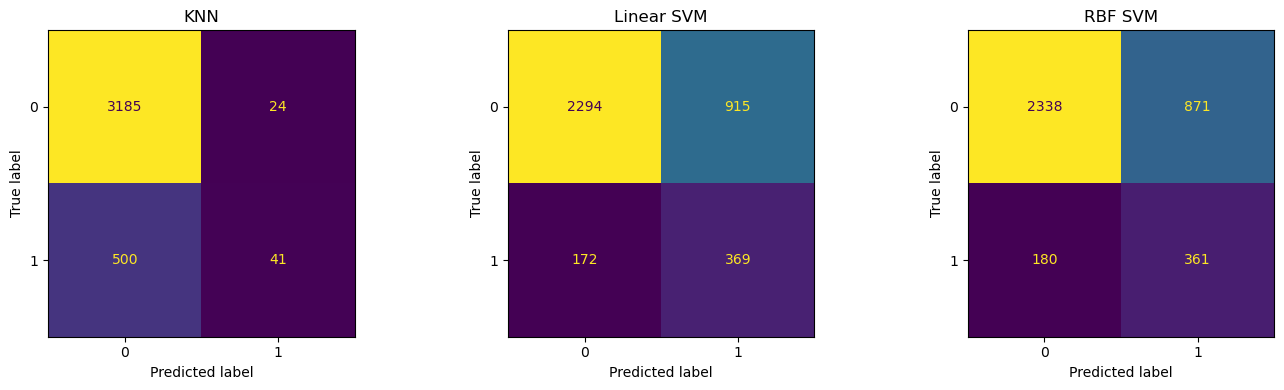

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

fig,ax=plt.subplots(1,3,figsize=(14,4))
for a,(name,m) in zip(ax,models.items()): ConfusionMatrixDisplay.from_estimator(m,Xte,y_test,ax=a,colorbar=False); a.set_title(name)
plt.tight_layout(); plt.show()

## 10. Threshold and capacity

Lower thresholds usually flag more patients and increase recall, but may reduce precision. The appropriate threshold depends on follow-up capacity, intervention cost, timing, and the cost of missed readmissions.

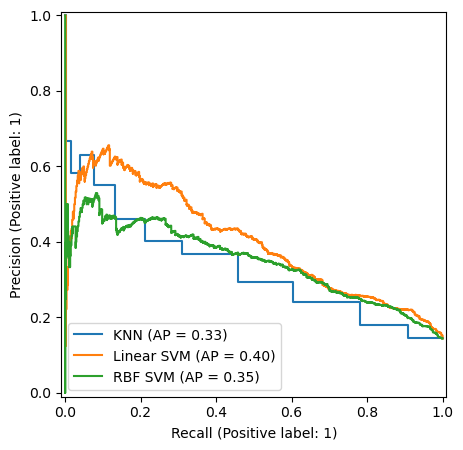

In [32]:
from sklearn.metrics import PrecisionRecallDisplay

fig,ax=plt.subplots(figsize=(7,5))
for name,m in models.items(): PrecisionRecallDisplay.from_estimator(m,Xte,y_test,name=name,ax=ax)
plt.show()

## 11. Responsible use

Before operational use, the model would need temporal and external validation, calibration, subgroup error analysis, privacy review, workflow testing, documentation, and human oversight. This notebook is for learning only.

## Review checklist
- [ ] Explain why `patient_id` is excluded.
- [ ] Explain stratification, imputation, and scaling.
- [ ] Describe `k`, `C`, `gamma`, and kernels.
- [ ] Interpret precision, recall, F1, and both error types.
- [ ] Explain why operational capacity affects model selection.